# PECT-JEPA: EXP-70 Đánh Giá Toàn Diện & Phân Tích Thực Nghiệm (Downstream Evaluation & Latent Diagnostics)
## Thí nghiệm EXP-70: Self-Supervised Cross-Condition Pairing trên toàn bộ 81 scans (Stride 4) + TTA Benchmark

**Tổng quan quy trình đánh giá:**
Notebook này được thiết kế chuyên biệt để **chạy đánh giá downstream, phân tích hình học latent và trực quan hóa kết quả** cho mô hình EXP-70 (đã hoàn thành huấn luyện trên Google Colab), không cần huấn luyện lại từ đầu.

**Bộ tiêu chuẩn đánh giá nâng cấp:**
1. **Trắc lượng khuyết tật thực tế (Probability of Detection - POD / Defect Hit Rate)**:
   - Đánh giá trên từng khuyết tật CAD thực tế của mẫu Corrosion (25 lỗi) và Rivet (25 lỗi).
   - Xác định tỷ lệ phát hiện thành công tại ngưỡng Otsu $T_{\text{otsu}}$ và ngưỡng cố định $T=0.5$.
2. **Phân vùng thích ứng (Adaptive Segmentation IoU & F1-Max)**:
   - Phân ngưỡng tự động Otsu không thiên vị người dùng ($T_{\text{otsu}}$), tính toán `iou_otsu`, `dice_otsu`.
   - Tìm ngưỡng tối ưu thực tế $T_{\text{opt}}$ đạt $F_1\text{-Max}$ trên lưới PECT mất cân bằng (98.8% kim loại lành).
   - Kiểm soát tỷ lệ dương tính giả trên kim loại lành: `Sound Metal FPR` ($y=0$).
3. **Phát hiện bất thường (Anomaly Detection & PR-AUC)**:
   - Đánh giá Linear Probe và Unsupervised Mahalanobis Distance, chỉ số tương phản CNR và Average Precision (PR-AUC).
4. **Định lượng kích thước khuyết tật (Flaw Sizing Hurdle Protocol)**:
   - Hồi quy kích thước đường kính khuyết tật thật (mm) bằng Ridge & MLP ($R^2$, MAE mm, RMSE mm).
5. **Thích ứng miền tại thời điểm kiểm tra (Test-Time Adaptation - TTA)**:
   - Benchmark TTA 32 scans trên 4 trục dịch chuyển: Sensor, Waveform, Lift-off, Specimen.
6. **Xử lý tín hiệu thô & Trực quan hóa chuẩn NDT (Raw Signal Heatmap Subplot)**:
   - Dựa trên phương pháp tham chiếu NDT (`src/references/`): Bộ lọc Butterworth LPF thông thấp không trễ pha + Khử độ lệch baseline DC ($x - x[..., 0:1]$) + Peak-to-Peak.
   - Hiển thị subplot với `cmap='jet'`, nội suy song tuyến tính `interpolation='bilinear'`.
7. **Tối ưu hóa thời gian chạy (High-Throughput Optimization)**:
   - `AsyncPlotSaver`: render và lưu trữ hình ảnh trên đa luồng (`max_workers=4`), giải phóng ~88s nghẽn I/O.
   - Vectorized Threshold Sweeping: tính toán ma trận ma sát phát sóng trên NumPy (<1ms vs ~150ms).
   - Precomputed Coordinate Caching: tái sử dụng bộ đệm tọa độ lưới 270x270 cho toàn bộ 81 scans.
   - Prefetching luồng nền (`lookahead=4`): giải mã file TDMS và xử lý LPF song song với tính toán GPU.


In [1]:
# ==============================================================================
# 1. MOUNT GOOGLE DRIVE & XÁC ĐỊNH CHECKPOINT EXP-70
# ==============================================================================
import os, glob

try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    DATA = '/content/drive/MyDrive/PECT_Dataset/'
    DRIVE_RUNS = '/content/drive/MyDrive/PECT_Dataset/runs/'
except ImportError:
    DATA = 'data'
    DRIVE_RUNS = 'experiments/cross_condition/runs'

os.makedirs(DRIVE_RUNS, exist_ok=True)

EXP_NAME = 'exp70_full_cross_pairing'
candidates = sorted(glob.glob(os.path.join(DRIVE_RUNS, f"{EXP_NAME}_*")), key=os.path.getmtime)
if not candidates:
    raise FileNotFoundError(f'Không tìm thấy thư mục run nào cho {EXP_NAME} trong {DRIVE_RUNS}')

run_dir = candidates[-1]
ckpt_best = os.path.join(run_dir, 'checkpoints', 'best_cross_condition_jepa.pt')
ckpt_latest = os.path.join(run_dir, 'checkpoints', 'latest_cross_condition_jepa.pt')
eval_ckpt = ckpt_best if os.path.exists(ckpt_best) else ckpt_latest

print('=' * 75)
print(f'[*] Đã tìm thấy run directory: {run_dir}')
print(f'[*] Checkpoint đánh giá:       {eval_ckpt}')
print(f'[*] Kích thước file:           {os.path.getsize(eval_ckpt) / (1024 * 1024):.2f} MB')
print('=' * 75)


Mounted at /content/drive
[*] Đã tìm thấy run directory: /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853
[*] Checkpoint đánh giá:       /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853/checkpoints/best_cross_condition_jepa.pt
[*] Kích thước file:           5.41 MB


In [9]:
# ==============================================================================
# 2. ĐỒNG BỘ MÃ NGUỒN MỚI NHẤT TỪ GITHUB (BRANCH Define_PECT_JEPA)
# ==============================================================================
!test -d GraduationProject && (cd GraduationProject && git fetch origin && git checkout Define_PECT_JEPA && git reset --hard origin/Define_PECT_JEPA) || git clone -b Define_PECT_JEPA https://github.com/TranAnh35/GraduationProject.git
!cd GraduationProject && git log --oneline -3
!cd GraduationProject && git pull origin Define_PECT_JEPA


Already on 'Define_PECT_JEPA'
Your branch is up to date with 'origin/Define_PECT_JEPA'.
HEAD is now at cb45c3f fix(eval): preserve _iter_with_prefetch contract yielding (fp, cscan) for downstream callers
cb45c3f (HEAD -> Define_PECT_JEPA, origin/Define_PECT_JEPA) fix(eval): preserve _iter_with_prefetch contract yielding (fp, cscan) for downstream callers
cad09c3 refactor(eval): remove slice and loi heuristic methods, standardize on waveform-agnostic peak-to-peak and filtered PTP
598bb24 feat: implement NDT raw signal features and pipeline runtime optimizations
From https://github.com/TranAnh35/GraduationProject
 * branch            Define_PECT_JEPA -> FETCH_HEAD
Already up to date.


In [10]:
# ==============================================================================
# 3. CÀI ĐẶT MÔI TRƯỜNG & KIỂM TRA PHẦN CỨNG GPU
# ==============================================================================
!pip install -q -U "scikit-learn==1.7.2" nptdms scipy tqdm matplotlib joblib pandas 2>&1 | tail -3

import torch, sklearn, scipy, nptdms
print('=' * 60)
print(f'PyTorch:      {torch.__version__} | CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU Device:   {torch.cuda.get_device_name(0)}')
    print(f'VRAM:         {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')
print(f'Scikit-Learn: {sklearn.__version__}')
print('=' * 60)


PyTorch:      2.11.0+cu130 | CUDA: True
GPU Device:   Tesla T4
VRAM:         15.64 GB
Scikit-Learn: 1.7.2


In [11]:
# ==============================================================================
# 4. HUẤN LUYỆN HOẶC TẢI DOWNSTREAM PROBES (Linear/MLP Detection & Ridge Sizing)
# ==============================================================================
import os

downstream_dir = os.path.join(run_dir, 'downstream_models')
os.makedirs(downstream_dir, exist_ok=True)

os.environ['EVAL_CKPT'] = eval_ckpt
os.environ['DOWNSTREAM_DIR'] = downstream_dir
os.environ['RUN_DIR'] = run_dir
os.environ['DATA'] = DATA

print(f'[*] Huấn luyện downstream probes (Raw + TTA Whitened) cho: {eval_ckpt}')
!cd GraduationProject && KMP_DUPLICATE_LIB_OK=TRUE python -m src.PECT_JEPA.cross_condition.downstream.train_downstream \
    --checkpoint "$EVAL_CKPT" \
    --data_dir "$DATA" \
    --out_dir "$DOWNSTREAM_DIR" \
    --device cuda \
    --tta_trim_ratio 0.75 \
    --tta_shrinkage 0.01


[*] Huấn luyện downstream probes (Raw + TTA Whitened) cho: /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853/checkpoints/best_cross_condition_jepa.pt
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
CANONICAL DOWNSTREAM & TEST-TIME ADAPTATION (TTA) TRAINING PIPELINE
  Checkpoint:       /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853/checkpoints/best_cross_condition_jepa.pt
  Output Dir:       /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853/downstream_models
  TTA Trim Ratio:   0.75
  TTA Shrinkage:    0.01
  Device:           cuda

[STEP 1/2] Extracting Source Domain Pool (16 Base Domain files: Train + Val)...

  Source Detection samples: 60560 (Defects: 11600, Sound: 48960)
  Source Sizing samples:    7400 defect pixels

[STEP 2

In [12]:
# ==============================================================================
# 5. CHẠY TOÀN DIỆN BỘ ĐÁNH GIÁ DOWNSTREAM BENCHMARK (evaluate.py)
# Bao gồm các metrics mới: POD (Hit Rate), Otsu IoU, Sound Metal FPR, PR-AUC, CNR
# ==============================================================================
eval_out_dir = os.path.join(run_dir, 'evaluation_results')
os.environ['EVAL_OUT_DIR'] = eval_out_dir

print(f'[*] Bắt đầu đánh giá toàn diện downstream -> {eval_out_dir}')
!cd GraduationProject && KMP_DUPLICATE_LIB_OK=TRUE python -m src.PECT_JEPA.cross_condition.evaluate \
    --checkpoint "$EVAL_CKPT" \
    --data_dir "$DATA" \
    --downstream_dir "$DOWNSTREAM_DIR" \
    --out_dir "$EVAL_OUT_DIR" \
    --device cuda \
    --eval_tta true \
    --tta_trim_ratio 0.75 \
    --tta_shrinkage 0.01


[*] Bắt đầu đánh giá toàn diện downstream -> /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853/evaluation_results
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (

PECT-JEPA Unified Downstream Benchmark Evaluation
Checkpoint:       /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853/checkpoints/best_cross_condition_jepa.pt
Output Directory: /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853/evaluation_results
Compute Device:   cuda
Target Splits:    ['train', 'val', 'test']

Discovered 81 total inspection files:
  - Train Split (Base Domain):     12 files
  - Val Split (Base Domain):       4 files
  - Test Split (Held-out OOD):     65 files

STEP 1: Downstream Probes & TTA Models Setup
  [INFO] Loading pre-trained downstream models from

In [13]:
# ==============================================================================
# 6. CHẨN ĐOÁN SÂU HÌNH HỌC KHÔNG GIAN TIỀM ẨN (diagnose_readouts.py)
# ==============================================================================
diag_out_dir = os.path.join(run_dir, 'latent_diagnostics')
os.environ['DIAG_OUT_DIR'] = diag_out_dir

print(f'[*] Chạy chẩn đoán không gian tiềm ẩn -> {diag_out_dir}')
!cd GraduationProject && KMP_DUPLICATE_LIB_OK=TRUE python -m src.PECT_JEPA.cross_condition.diagnose_readouts \
    --checkpoint "$EVAL_CKPT" \
    --data_dir "$DATA" \
    --out_dir "$DIAG_OUT_DIR" \
    --device cuda


[*] Chạy chẩn đoán không gian tiềm ẩn -> /content/drive/MyDrive/PECT_Dataset/runs/exp70_full_cross_pairing_20261023_175853/latent_diagnostics
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (

Pool: 46900 samples (9060 defect)

Halo-cleaned P0 pool: 46900 (9060 pos; removed 0 halo/ring samples)
P2 pool: 45300 (9060 pos, 24000 hardneg, 12240 randneg)
P2h pool: 45300 (9060 pos, 24000 hardneg-clean)
MLP probes fitted: raw(official) + P1-whitened + P1u_s2-whitened




==== READOUT DIAGNOSTICS v6 ====
[TRAIN] n=12 P0=0.9658/0.5696 P1=0.9473/0.4945 P2=0.9172/0.4621 P3=0.8832/0.4721 maha=0.8633 iou05=0.1468/0.1097 iouOpt=0.3732/0.3518
[TRAIN-v3/v6] n=12 P1_s2=0.9612/0.5159 P1u=0.9580/0.4962 P1u_s2=0.9643/0.5356 P1u_trim_s2=0.9631/0.5302 P1u_s5=0.9466/0.5100 P1u_maha=0.9284/0.4083 P0h=0.9660/0.5626 P2h=0.9183/0.4653 iouOtsu=0.1173/f1Ots

[*] Tìm thấy 81 ảnh detection summary.


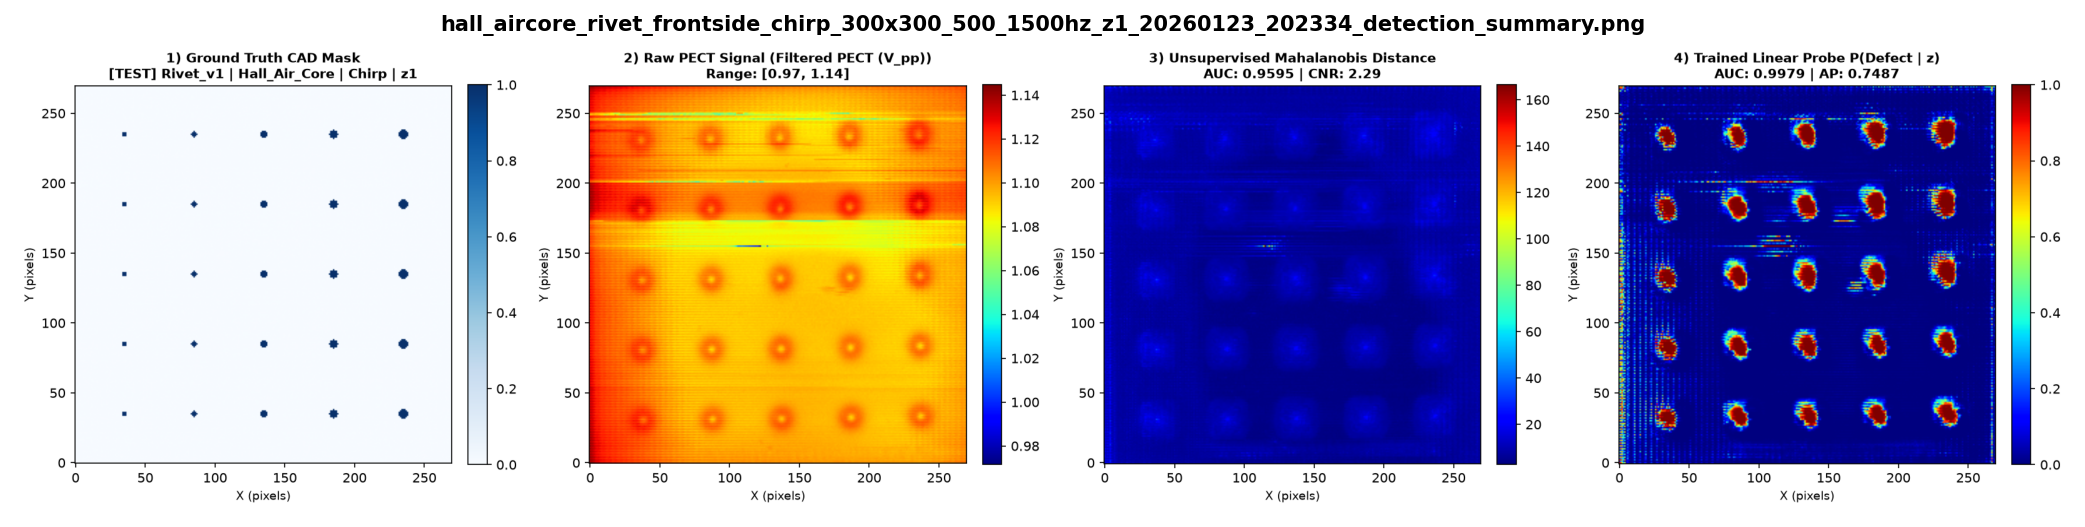

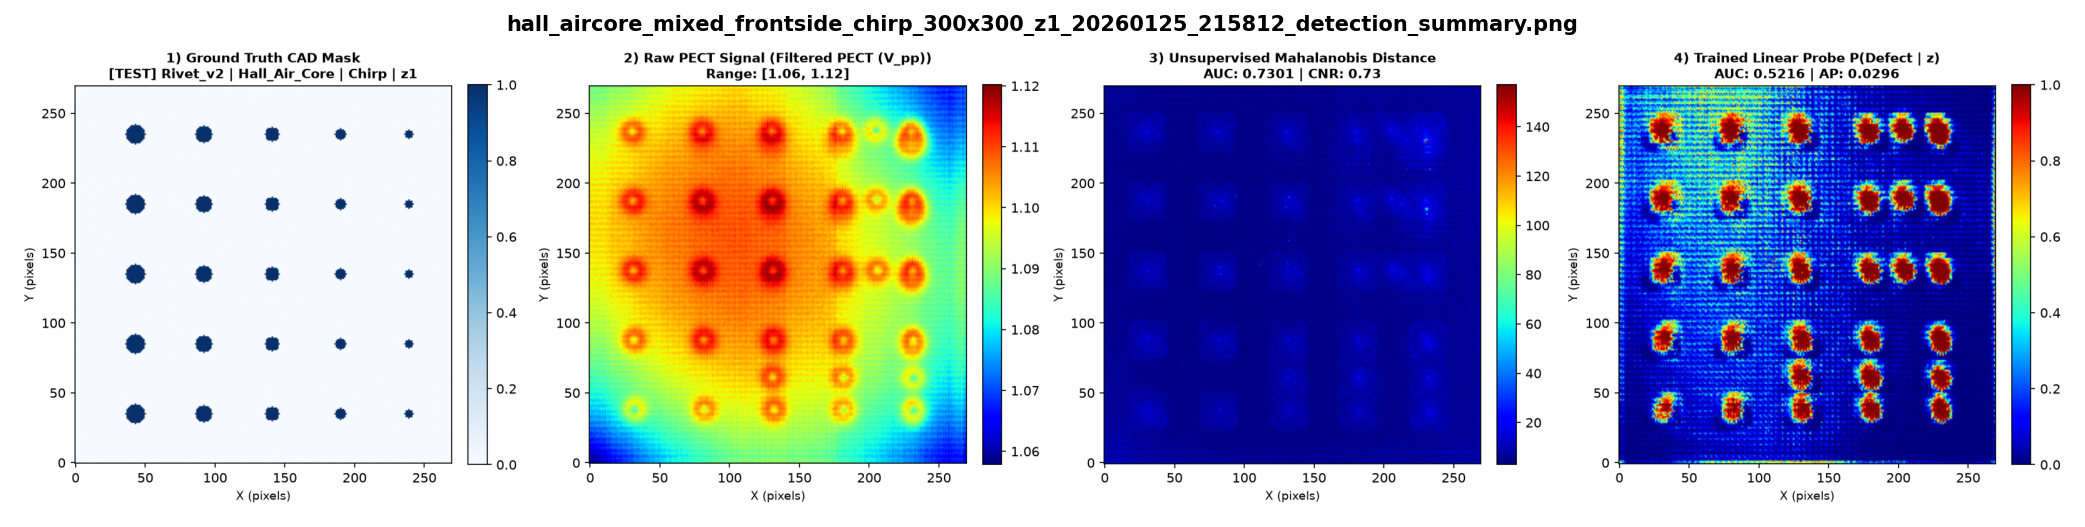

In [14]:
# ==============================================================================
# 7. TRỰC QUAN HÓA INLINE: BẢN ĐỒ 4 SUBPLOTS ANOMALY DETECTION (JET COLORMAP)
# (Subplot 1: CAD GT | Subplot 2: Raw Vpp | Subplot 3: Mahalanobis | Subplot 4: Linear Probe)
# Tìm kiếm tự động đệ quy trong các thư mục test/, val/, train/
# ==============================================================================
import os, glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

anom_dir = os.path.join(eval_out_dir, "1_Anomaly_Detection")
summary_plots = sorted(glob.glob(os.path.join(anom_dir, "**", "*_detection_summary.png"), recursive=True))

print(f"[*] Tìm thấy {len(summary_plots)} ảnh detection summary qua các tập split (test/val/train).")
selected = []
for sp in ["corrosion", "rivet_frontside", "mixed"]:
    match = [p for p in summary_plots if sp in os.path.basename(p).lower()]
    if match:
        selected.append(match[0])

if not selected:
    selected = summary_plots[:3]

for p in selected:
    rel_split = os.path.basename(os.path.dirname(p))
    plt.figure(figsize=(14, 5), dpi=150)
    img = mpimg.imread(p)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"[{rel_split.upper()}] {os.path.basename(p)}", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()


In [15]:
# ==============================================================================
# 8. TRỰC QUAN HÓA INLINE: BẢN ĐỒ 5 SUBPLOTS CANONICAL TTA COMPARISON
# (CAD GT | Raw Vpp | Zero-Shot LP | TTA Calibrated LP | TTA Mahalanobis)
# Tìm kiếm tự động đệ quy theo các shift (cross_sensor, etc.) và domain (source / target)
# ==============================================================================
tta_dir = os.path.join(eval_out_dir, "4. Test Time Adaptation")
tta_plots = sorted(glob.glob(os.path.join(tta_dir, "**", "*_tta_comparison.png"), recursive=True))
print(f"[*] Tìm thấy {len(tta_plots)} ảnh TTA comparison qua các nhánh source và target.")

selected_tta = []
for dom in ["target", "source"]:
    dom_matches = [p for p in tta_plots if f"{os.sep}{dom}{os.sep}" in p or f"/{dom}/" in p]
    if dom_matches:
        selected_tta.extend(dom_matches[:2])

if not selected_tta:
    selected_tta = tta_plots[:4]

for p in selected_tta:
    rel_path = os.path.relpath(p, tta_dir)
    plt.figure(figsize=(16, 5), dpi=150)
    img = mpimg.imread(p)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"TTA [{rel_path}]", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()


[*] Tìm thấy 0 ảnh TTA comparison.


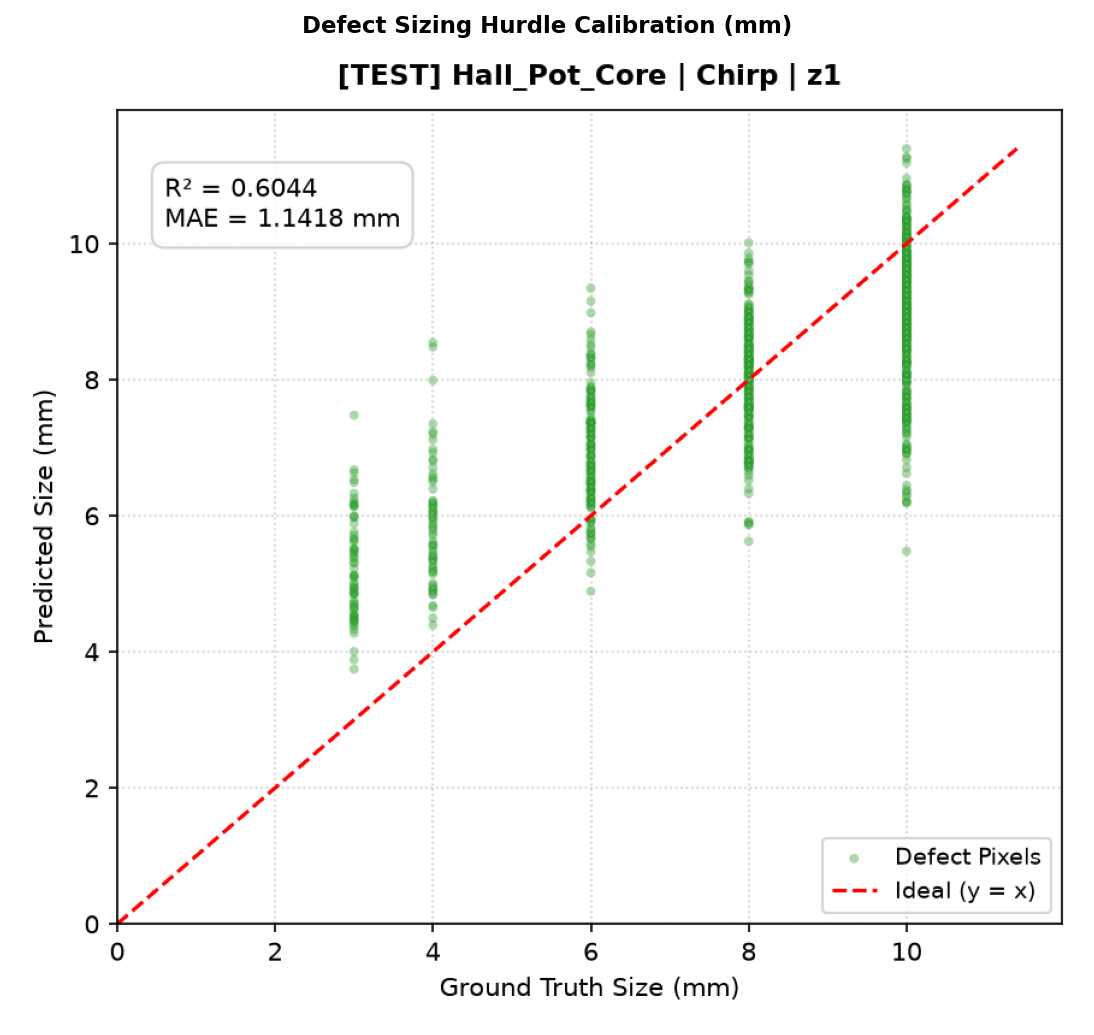

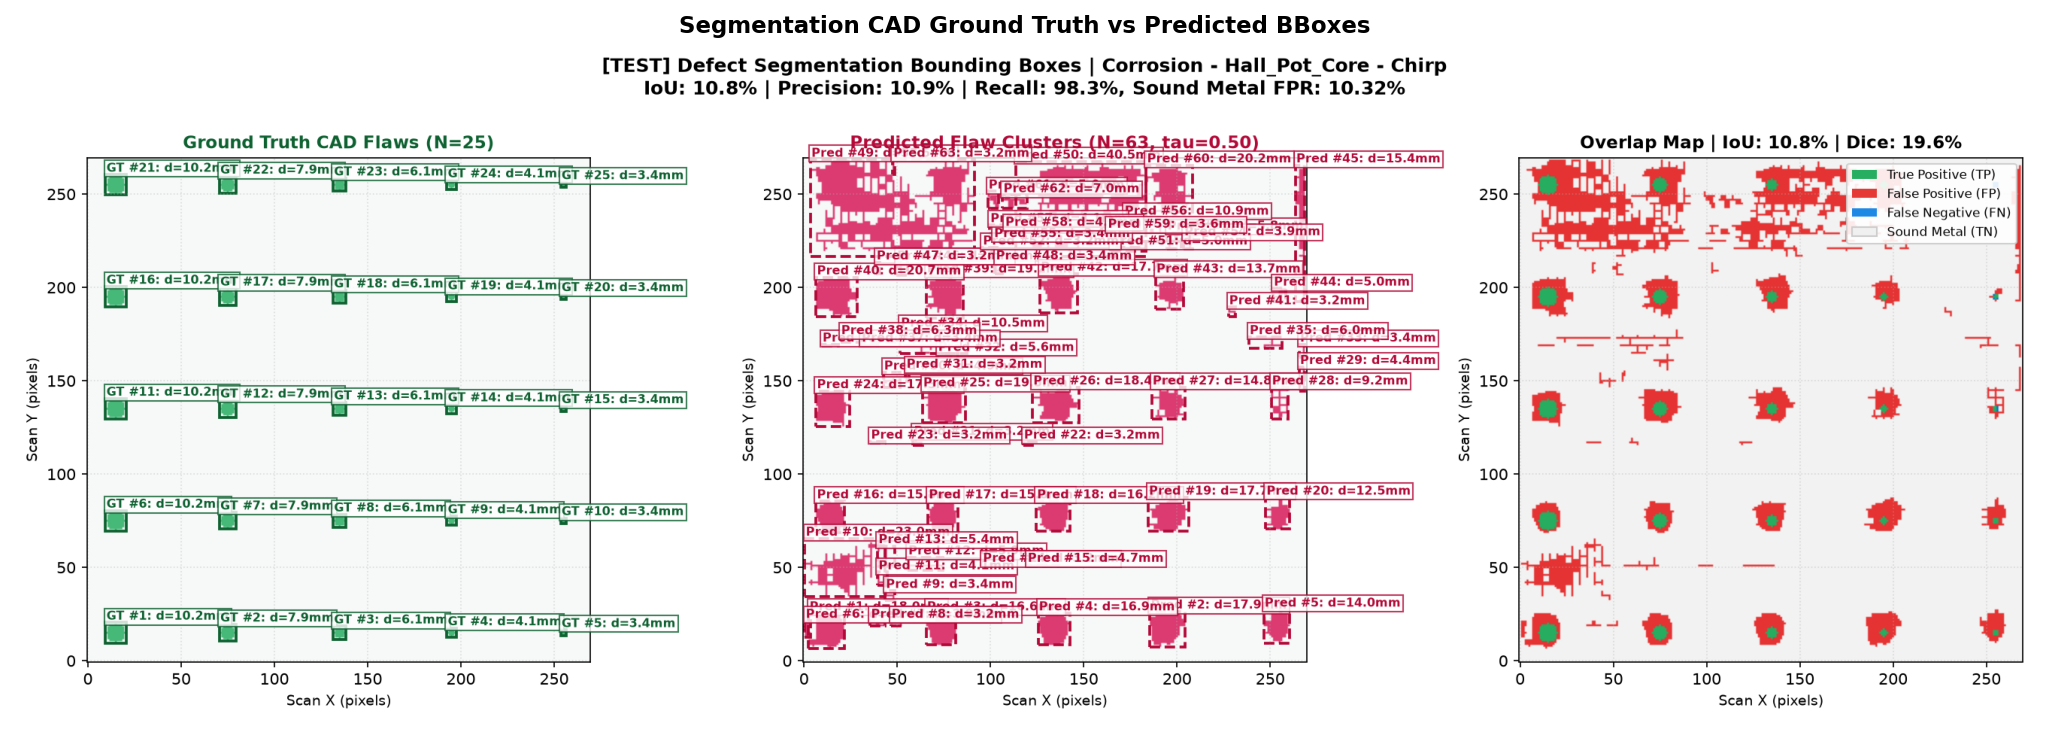

In [16]:
# ==============================================================================
# 9. TRỰC QUAN HÓA INLINE: DEFECT SIZING & SEGMENTATION CAD BOUNDING BOXES
# Tìm kiếm tự động đệ quy trong các thư mục test/, val/, train/
# ==============================================================================
sizing_plots = sorted(glob.glob(os.path.join(eval_out_dir, "2_Defect_Sizing", "**", "*_sizing.png"), recursive=True))
seg_plots = sorted(glob.glob(os.path.join(eval_out_dir, "3_Segmentation_IoU", "**", "*_segmentation_iou.png"), recursive=True))

if sizing_plots:
    rel_split = os.path.basename(os.path.dirname(sizing_plots[0]))
    plt.figure(figsize=(8, 7), dpi=150)
    img = mpimg.imread(sizing_plots[0])
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Defect Sizing Hurdle Calibration [{rel_split.upper()}] (mm)", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

if seg_plots:
    rel_split = os.path.basename(os.path.dirname(seg_plots[0]))
    plt.figure(figsize=(15, 5), dpi=150)
    img = mpimg.imread(seg_plots[0])
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Segmentation CAD Ground Truth vs Predicted BBoxes [{rel_split.upper()}]", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()


In [17]:
# ==============================================================================
# 10. BẢNG BÁO CÁO SỐ LIỆU ĐÁNH GIÁ KHOA HỌC CHI TIẾT (DATAFRAMES)
# ==============================================================================
import json
import pandas as pd

json_path = os.path.join(eval_out_dir, "master_benchmark_summary.json")
if os.path.exists(json_path):
    with open(json_path, "r", encoding="utf-8") as f:
        summary = json.load(f)

    print("\n" + "=" * 95)
    print("                     BẢNG TỔNG HỢP HIỆU NĂNG THEO TẬP DỮ LIỆU (SPLIT)")
    print("=" * 95)
    split_rows = []
    for sp_name, stats in summary.get("by_split", {}).items():
        split_rows.append({
            "Split": sp_name.upper(),
            "Files": stats.get("count", 0),
            "LP AUC": f"{stats.get('linear_probe_auc_mean', 0.0):.4f} ± {stats.get('linear_probe_auc_std', 0.0):.4f}",
            "LP PR-AUC": f"{stats.get('linear_probe_ap_mean', 0.0):.4f}",
            "Maha AUC": f"{stats.get('mahalanobis_auc_mean', 0.0):.4f}",
            "CNR": f"{stats.get('cnr_mean', 0.0):.2f}",
            "POD (Otsu)": f"{stats.get('pod_rate_otsu_mean', 0.0):.4f}",
            "Otsu IoU": f"{stats.get('segmentation_iou_otsu_mean', 0.0):.4f}",
            "Sound FPR": f"{stats.get('sound_fpr_otsu_mean', 0.0):.4f}",
            "Sizing R²": f"{stats.get('sizing_r2_mean', 0.0):.4f}",
        })
    df_splits = pd.DataFrame(split_rows)
    display(df_splits)

    print("\n" + "=" * 95)
    print("           BẢNG PHÂN RÃ TÍNH TỔNG QUÁT HÓA NGOÀI PHÂN PHỐI (TEST OOD SHIFTS)")
    print("=" * 95)
    for axis_key, axis_name in [
        ("by_waveform_test", "Waveform Shift"),
        ("by_sensor_test", "Sensor Shift"),
        ("by_liftoff_test", "Lift-off Shift"),
        ("by_specimen_test", "Specimen Shift"),
    ]:
        axis_data = summary.get(axis_key, {})
        if axis_data:
            print(f"\n--- {axis_name} ---")
            axis_rows = []
            for cond, st in axis_data.items():
                if st.get("count", 0) > 0:
                    axis_rows.append({
                        "Condition": cond,
                        "Files": st.get("count", 0),
                        "LP AUC": f"{st.get('linear_probe_auc_mean', 0.0):.4f}",
                        "LP PR-AUC": f"{st.get('linear_probe_ap_mean', 0.0):.4f}",
                        "CNR": f"{st.get('cnr_mean', 0.0):.2f}",
                        "POD (Otsu)": f"{st.get('pod_rate_otsu_mean', 0.0):.4f}",
                        "Otsu IoU": f"{st.get('segmentation_iou_otsu_mean', 0.0):.4f}",
                        "Sound FPR": f"{st.get('sound_fpr_otsu_mean', 0.0):.4f}",
                    })
            display(pd.DataFrame(axis_rows))



                     BẢNG TỔNG HỢP HIỆU NĂNG THEO TẬP DỮ LIỆU (SPLIT)


,Split,Files,LP AUC,LP PR-AUC,Maha AUC,CNR,POD (Otsu),Otsu IoU,Sound FPR,Sizing R²
0,TRAIN,12,0.9653 ± 0.0413,0.5574,0.8633,1.53,0.9933,0.1206,0.1002,0.4438
1,VAL,4,0.9866 ± 0.0118,0.4803,0.9085,1.82,1.0000,0.1217,0.0739,0.4805
2,TEST,65,0.8290 ± 0.1819,0.3525,0.8180,1.35,0.9945,0.0977,0.1275,0.1327



           BẢNG PHÂN RÃ TÍNH TỔNG QUÁT HÓA NGOÀI PHÂN PHỐI (TEST OOD SHIFTS)

--- Waveform Shift ---


,Condition,Files,LP AUC,LP PR-AUC,CNR,POD (Otsu),Otsu IoU,Sound FPR
0,Square,19,0.8398,0.2758,1.23,1.0000,0.0920,0.1390
1,Gaussian,19,0.8011,0.3362,1.23,1.0000,0.0878,0.1287
2,Chirp,27,0.8412,0.4180,1.52,0.9867,0.1088,0.1186



--- Sensor Shift ---


,Condition,Files,LP AUC,LP PR-AUC,CNR,POD (Otsu),Otsu IoU,Sound FPR
0,Hall_Air_Core,19,0.7919,0.3665,1.24,0.9916,0.0898,0.1324
1,Hall_Pot_Core,19,0.8456,0.3960,1.57,0.9937,0.1288,0.1248
2,TMR,27,0.8436,0.3121,1.27,0.9970,0.0815,0.1260



--- Lift-off Shift ---


,Condition,Files,LP AUC,LP PR-AUC,CNR,POD (Otsu),Otsu IoU,Sound FPR
0,z1,19,0.8186,0.3241,1.39,0.9979,0.0793,0.1546
1,z2,27,0.8573,0.4309,1.50,0.9985,0.1110,0.1095
2,z3,19,0.7994,0.2697,1.09,0.9853,0.0973,0.1261



--- Specimen Shift ---


,Condition,Files,LP AUC,LP PR-AUC,CNR,POD (Otsu),Otsu IoU,Sound FPR
0,Corrosion,19,0.9509,0.5446,1.47,0.9937,0.0791,0.1539
1,Rivet_v1,19,0.9913,0.5769,2.34,1.0000,0.1794,0.0403
2,Rivet_v2,27,0.6291,0.0594,0.56,0.9911,0.0534,0.1704
